In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df1 = pd.read_csv("/content/gossipcop_fake.csv")
print(df1.head(5))

                     id                                           news_url  \
0  gossipcop-2493749932  www.dailymail.co.uk/tvshowbiz/article-5874213/...   
1  gossipcop-4580247171  hollywoodlife.com/2018/05/05/paris-jackson-car...   
2   gossipcop-941805037  variety.com/2017/biz/news/tax-march-donald-tru...   
3  gossipcop-2547891536  www.dailymail.co.uk/femail/article-3499192/Do-...   
4  gossipcop-5476631226  variety.com/2018/film/news/list-2018-oscar-nom...   

                                               title  \
0  Did Miley Cyrus and Liam Hemsworth secretly ge...   
1  Paris Jackson & Cara Delevingne Enjoy Night Ou...   
2  Celebrities Join Tax March in Protest of Donal...   
3  Cindy Crawford's daughter Kaia Gerber wears a ...   
4      Full List of 2018 Oscar Nominations – Variety   

                                           tweet_ids  
0  284329075902926848\t284332744559968256\t284335...  
1  992895508267130880\t992897935418503169\t992899...  
2  853359353532829696\t853359

In [3]:
df2 = pd.read_csv("/content/gossipcop_real.csv")
print(df2.head(5))

                 id                                           news_url  \
0  gossipcop-882573  https://www.brides.com/story/teen-mom-jenelle-...   
1  gossipcop-875924  https://www.dailymail.co.uk/tvshowbiz/article-...   
2  gossipcop-894416        https://en.wikipedia.org/wiki/Quinn_Perkins   
3  gossipcop-857248  https://www.refinery29.com/en-us/2018/03/19192...   
4  gossipcop-884684  https://www.cnn.com/2017/10/04/entertainment/c...   

                                               title  \
0  Teen Mom Star Jenelle Evans' Wedding Dress Is ...   
1  Kylie Jenner refusing to discuss Tyga on Life ...   
2                                      Quinn Perkins   
3  I Tried Kim Kardashian's Butt Workout & Am For...   
4  Celine Dion donates concert proceeds to Vegas ...   

                                           tweet_ids  
0  912371411146149888\t912371528343408641\t912372...  
1  901989917546426369\t901989992074969089\t901990...  
2  931263637246881792\t931265332022579201\t931265... 

In [4]:
df3 = pd.read_csv("/content/politifact_fake.csv")
df4 = pd.read_csv("/content/politifact_real.csv")
print(df3.head(5))
print(df4.head(5))

                id                                           news_url  \
0  politifact15014          speedtalk.com/forum/viewtopic.php?t=51650   
1  politifact15156  politics2020.info/index.php/2018/03/13/court-o...   
2  politifact14745  www.nscdscamps.org/blog/category/parenting/467...   
3  politifact14355  https://howafrica.com/oscar-pistorius-attempts...   
4  politifact15371  http://washingtonsources.org/trump-votes-for-d...   

                                               title  \
0  BREAKING: First NFL Team Declares Bankruptcy O...   
1  Court Orders Obama To Pay $400 Million In Rest...   
2  UPDATE: Second Roy Moore Accuser Works For Mic...   
3         Oscar Pistorius Attempts To Commit Suicide   
4        Trump Votes For Death Penalty For Being Gay   

                                           tweet_ids  
0  937349434668498944\t937379378006282240\t937380...  
1  972666281441878016\t972678396575559680\t972827...  
2  929405740732870656\t929439450400264192\t929439...  
3  8

In [5]:
print(df1.shape)
print(df2.shape)
print(df3.shape)
print(df4.shape)

(5323, 4)
(16817, 4)
(432, 4)
(624, 4)


In [6]:
print("the null values for df1:",df1.isnull().sum())
print("the null values for df2:",df2.isnull().sum())
print("the null values for df3:",df3.isnull().sum())
print("the null values for df4:",df4.isnull().sum())

the null values for df1: id             0
news_url     256
title          0
tweet_ids    188
dtype: int64
the null values for df2: id              0
news_url       13
title           0
tweet_ids    1058
dtype: int64
the null values for df3: id            0
news_url      4
title         0
tweet_ids    40
dtype: int64
the null values for df4: id             0
news_url      57
title          0
tweet_ids    215
dtype: int64


In [7]:
print(df1.isnull().sum().sum())
print(df2.isnull().sum().sum())
print(df3.isnull().sum().sum())
print(df4.isnull().sum().sum())


444
1071
44
272


In [8]:
df1["representation"]=1
df2["representation"]=0
df3["representation"]=1
df4["representation"]=0

In [9]:
df = pd.concat([df1,df2,df3,df4], ignore_index=True)
print(df.head(5))
print(df.shape)

                     id                                           news_url  \
0  gossipcop-2493749932  www.dailymail.co.uk/tvshowbiz/article-5874213/...   
1  gossipcop-4580247171  hollywoodlife.com/2018/05/05/paris-jackson-car...   
2   gossipcop-941805037  variety.com/2017/biz/news/tax-march-donald-tru...   
3  gossipcop-2547891536  www.dailymail.co.uk/femail/article-3499192/Do-...   
4  gossipcop-5476631226  variety.com/2018/film/news/list-2018-oscar-nom...   

                                               title  \
0  Did Miley Cyrus and Liam Hemsworth secretly ge...   
1  Paris Jackson & Cara Delevingne Enjoy Night Ou...   
2  Celebrities Join Tax March in Protest of Donal...   
3  Cindy Crawford's daughter Kaia Gerber wears a ...   
4      Full List of 2018 Oscar Nominations – Variety   

                                           tweet_ids  representation  
0  284329075902926848\t284332744559968256\t284335...               1  
1  992895508267130880\t992897935418503169\t992899...

combined together all the data frames into one df

In [10]:
print(df.isnull().sum())

id                   0
news_url           330
title                0
tweet_ids         1501
representation       0
dtype: int64


In [11]:
df = df.drop_duplicates()

print(df.shape,df.isnull().sum())

(23196, 5) id                   0
news_url           330
title                0
tweet_ids         1501
representation       0
dtype: int64


no duplicated rows so there were no deduction from the total amount of rows.

In [12]:
df["news_url"] = df["news_url"].fillna("")
df["tweet_ids"] = df["tweet_ids"].fillna("")

print(df.isnull().sum())

id                0
news_url          0
title             0
tweet_ids         0
representation    0
dtype: int64


### Phase 2: Prepare article text and publisher


In [13]:
from urllib.parse import urlparse

def get_publisher(url):
    if not isinstance(url, str) or not url.strip():
        return ""
    try:
        domain = urlparse(url if url.startswith(("http://", "https://")) else "https://" + url).netloc.lower()
        if domain.startswith("www."):
            domain = domain[4:]
        return domain
    except Exception:
        return ""

df["publisher"] = df["news_url"].apply(get_publisher)
print("Rows:", len(df))
print("Rows with a publisher:", (df["publisher"] != "").sum())
print(df[["title", "news_url", "publisher", "representation"]].head())

Rows: 23196
Rows with a publisher: 22866
                                               title  \
0  Did Miley Cyrus and Liam Hemsworth secretly ge...   
1  Paris Jackson & Cara Delevingne Enjoy Night Ou...   
2  Celebrities Join Tax March in Protest of Donal...   
3  Cindy Crawford's daughter Kaia Gerber wears a ...   
4      Full List of 2018 Oscar Nominations – Variety   

                                            news_url          publisher  \
0  www.dailymail.co.uk/tvshowbiz/article-5874213/...    dailymail.co.uk   
1  hollywoodlife.com/2018/05/05/paris-jackson-car...  hollywoodlife.com   
2  variety.com/2017/biz/news/tax-march-donald-tru...        variety.com   
3  www.dailymail.co.uk/femail/article-3499192/Do-...    dailymail.co.uk   
4  variety.com/2018/film/news/list-2018-oscar-nom...        variety.com   

   representation  
0               1  
1               1  
2               1  
3               1  
4               1  


### Retrieve article text


In [14]:
!pip -q install requests beautifulsoup4

In [16]:
import time
import requests
from bs4 import BeautifulSoup

# First test on 200 rows. Change to None to attempt all rows.
MAX_ARTICLES = 200

work_df = df.copy()
if MAX_ARTICLES is not None:
    work_df = work_df.sample(MAX_ARTICLES, random_state=42).copy()

HEADERS = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                  "(KHTML, like Gecko) Chrome/120.0 Safari/537.36"
}

def get_article_text(url):
    if not isinstance(url, str) or not url.strip():
        return ""
    if not url.startswith(("http://", "https://")):
        url = "https://" + url
    try:
        response = requests.get(url, headers=HEADERS, timeout=10)
        if response.status_code != 200:
            return ""
        if not response.encoding or response.encoding.lower() == "iso-8859-1":
            response.encoding = response.apparent_encoding

        soup = BeautifulSoup(response.text, "html.parser")

        # remove parts of the page that are not article content
        for tag in soup(["script", "style", "noscript", "nav", "header", "footer", "aside", "form"]):
            tag.decompose()

        # prefer the <article> tag if the page has one, otherwise use the whole page
        container = soup.find("article") or soup
        paragraphs = [p.get_text(" ", strip=True) for p in container.find_all("p")]
        paragraphs = [p for p in paragraphs if len(p) >= 40]   # skip menu/button/caption fragments

        return "\n".join(paragraphs).strip()
    except Exception:
        return ""

article_texts = []
for i, url in enumerate(work_df["news_url"], start=1):
    article_texts.append(get_article_text(url))
    if i % 25 == 0:
        print(f"Processed {i}/{len(work_df)} articles")

work_df["article_text"] = article_texts
print("Articles attempted:", len(work_df))
print("Articles with text:", (work_df["article_text"].str.len() > 0).sum())
print("Articles without text:", (work_df["article_text"].str.len() == 0).sum())

Processed 25/200 articles
Processed 50/200 articles
Processed 75/200 articles
Processed 100/200 articles
Processed 125/200 articles
Processed 150/200 articles
Processed 175/200 articles
Processed 200/200 articles
Articles attempted: 200
Articles with text: 94
Articles without text: 106


### Clean and save the Phase 2 dataset


In [17]:
clean_df = work_df.copy()

clean_df["title"] = clean_df["title"].fillna("").astype(str).str.strip()
clean_df["article_text"] = clean_df["article_text"].fillna("").astype(str).str.strip()
clean_df["publisher"] = clean_df["publisher"].fillna("").astype(str)

clean_df = clean_df[clean_df["article_text"].str.len() >= 100]
clean_df = clean_df.drop_duplicates(subset=["article_text"])
clean_df = clean_df.reset_index(drop=True)

output_file = "fakenewsnet_cleaned.csv"
clean_df.to_csv(output_file, index=False)

print("Cleaned dataset shape:", clean_df.shape)
print("Label counts:")
print(clean_df["representation"].value_counts())
print("Saved to:", output_file)
clean_df[["title", "publisher", "representation", "article_text"]].head()

Cleaned dataset shape: (94, 7)
Label counts:
representation
0    72
1    22
Name: count, dtype: int64
Saved to: fakenewsnet_cleaned.csv


,title,publisher,representation,article_text
0,Will Bindi Irwin Get Married to Boyfriend Chan...,usmagazine.com,1,"Bling, bling, will she get a ring? The Irwin f..."
1,Bob Harper: Howard Stern Reached Out to Me Aft...,usmagazine.com,0,Sending him love! Bob Harper revealed the surp...
2,'The X-Files': What Did Scully Whisper to Mulder?,hollywoodreporter.com,0,[This story contains spoilers from the March 1...
3,"Confirmed: Meghan & Harry - Yes, it's twins",newidea.com.au,1,New Idea reported last week that newlyweds Pri...
4,Reese Witherspoon and Other Victims of Celeb P...,dailynews.news,0,"Kèo bóng đá hôm nay cập nhật kèo nhà cái, tỷ l..."


In [18]:
print("Unique publishers with article text:", clean_df["publisher"].nunique())
print("Rows by label after cleaning:")
print(clean_df["representation"].value_counts())

Unique publishers with article text: 60
Rows by label after cleaning:
representation
0    72
1    22
Name: count, dtype: int64


missing/null value rows are filled with .fillna("") for the cols of news_url and tweet_ids

In [19]:
print(df.head(50),df.tail(10))

                      id                                           news_url  \
0   gossipcop-2493749932  www.dailymail.co.uk/tvshowbiz/article-5874213/...   
1   gossipcop-4580247171  hollywoodlife.com/2018/05/05/paris-jackson-car...   
2    gossipcop-941805037  variety.com/2017/biz/news/tax-march-donald-tru...   
3   gossipcop-2547891536  www.dailymail.co.uk/femail/article-3499192/Do-...   
4   gossipcop-5476631226  variety.com/2018/film/news/list-2018-oscar-nom...   
5   gossipcop-5189580095  www.townandcountrymag.com/society/tradition/a1...   
6   gossipcop-9588339534  www.foxnews.com/entertainment/2016/12/16/bigge...   
7   gossipcop-8753274298  www.eonline.com/news/958257/caitlyn-jenner-add...   
8   gossipcop-8105333868  www.inquisitr.com/3871816/taylor-swift-reporte...   
9   gossipcop-2803748870  www.huffingtonpost.com/entry/kate-mckinnon-the...   
10  gossipcop-7312096991  www.msn.com/en-us/music/celebrity/miley-cyrus-...   
11  gossipcop-5328748354                yournewswire

representation
0    17441
1     5755
Name: count, dtype: int64


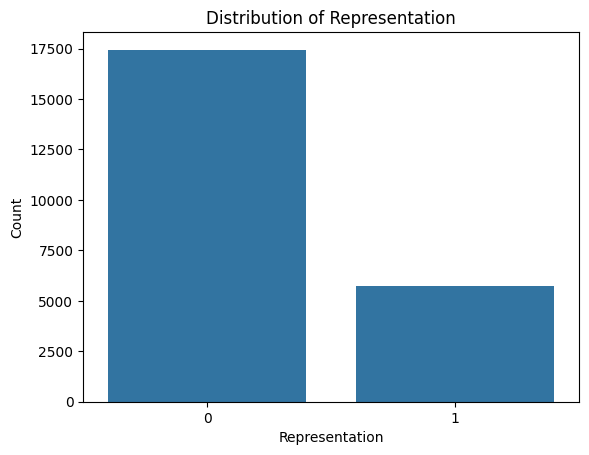

In [20]:
print(df["representation"].value_counts())
sns.countplot(data=df, x="representation")
plt.title("Distribution of Representation")
plt.xlabel("Representation")
plt.ylabel("Count")
plt.show()

it shows the amount of fake representation rows and real representation of rows

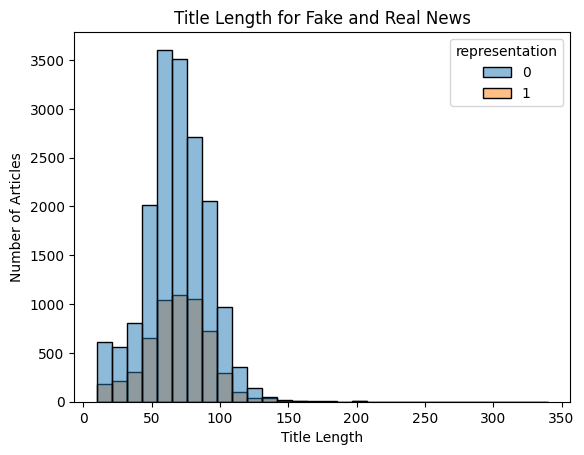

In [21]:
df["title_length"] = df["title"].fillna("").astype(str).str.len()

sns.histplot(data=df, x="title_length", hue="representation", bins=30)
plt.title("Title Length for Fake and Real News")
plt.xlabel("Title Length")
plt.ylabel("Number of Articles")
plt.show()

it shows the evident length difference between fake and real news title legnth and it shows that the fake ones have larger title length
